## 0. Library

This section imports the libraries needed for the full audio-processing pipeline. They cover file
handling, numerical computation, metadata management, audio loading/analysis, audio export, and
basic dataset preparation.

| Library | Purpose |
|---|---|
| `os` | Handles file paths, folder creation, and directory traversal. |
| `shutil` | Copies selected audio files for before/after comparison samples. |
| `numpy` | Performs numerical operations on audio arrays, such as RMS, clipping, and statistics. |
| `pandas` | Reads metadata files and stores preprocessing/feature results in structured tables. |
| `librosa` | Loads audio, removes silence, resamples signals, and extracts acoustic features. |
| `pydub.AudioSegment` | Converts processed NumPy audio arrays back into exportable audio files such as MP3. |

These libraries are used to connect the whole workflow: metadata is read with `pandas`, audio files
are found with `os`, loaded and processed with `librosa`/`numpy`, exported with `pydub`, and selected
examples are copied with `shutil` for manual inspection.


In [1]:
import os
import numpy as np
import pandas as pd
import librosa
from pydub import AudioSegment
import shutil
from scipy import stats
import matplotlib.pyplot as plt


## 1. Import and Output Dataset

This section defines the main input and output paths used throughout the pipeline. The original
dataset folder is selected first, then all required files and folders are built from that path so the
rest of the code can run consistently.

The input metadata file is `final_metadata.csv`, which contains the list of audio files and their
labels. A separate preprocessing folder is then created to store cleaned audio files, the updated
metadata report, the final feature dataset, analysis outputs, and before/after comparison samples.

| Path / Variable | Purpose |
|---|---|
| `dataset_dir` | Main folder containing the original dataset. |
| `metadata_path` | Path to the original metadata file, `final_metadata.csv`. |
| `preprocessed_root_dir` | Main output folder for all processed files and reports. |
| `output_dir` | Stores the cleaned and normalized audio files. |
| `report_path` / `preprocessed_metadata_path` | Stores the preprocessing report with status, flags, and output file paths. |
| `features_csv` | Stores the final extracted feature dataset. |
| `analysis_dir` | Stores plots and analysis outputs. |
| `sample_before_dir` / `sample_after_dir` | Store before/after examples for checking silence removal quality. |

Keeping all outputs inside `preprocessed_root_dir` makes the project easier to manage and separates
the original dataset from the generated files.


In [2]:

# change the dataset directory. ============================
# Set raw dataset directory (can be overridden via DATASET_DIR environment variable)
dataset_dir = os.environ.get('DATASET_DIR', r'C:\Users\AFSHIN\Desktop\Final-Project-Dataset')
# ==========================================================

metadata_path = os.path.join(dataset_dir,"final_metadata.csv")

preprocessed_root_dir = os.path.join(
    dataset_dir,
    "Final-Project-Dataset-Preprocessed"
)

features_csv = os.path.join(
    preprocessed_root_dir,
    "final_feature_dataset.csv"
)

analysis_dir = os.path.join(
    preprocessed_root_dir,
    "analysis_outputs"
)

preprocessed_metadata_path = os.path.join(
    preprocessed_root_dir,
    "preprocessed_final_metadata.csv"
)

features_csv = os.path.join(
    preprocessed_root_dir,
    "final_feature_dataset.csv"
)

output_dir=os.path.join(preprocessed_root_dir, "preprocessed_audio")
report_path = os.path.join(preprocessed_root_dir,"preprocessed_final_metadata.csv")

sample_dir=os.path.join(preprocessed_root_dir,"comparison_samples")
sample_before_dir=os.path.join(sample_dir,"before")
sample_after_dir=os.path.join(sample_dir,"after")


## 2. Preprocessing

This section prepares the original MP3 files for feature extraction. Each audio file is loaded at
16 kHz in mono format, leading and trailing silence are removed, and the remaining signal is
peak-normalized to make volume levels more consistent across the dataset.

The code also calculates several quality indicators for each file, such as duration, RMS energy,
zero crossing rate, and spectral centroid. Based on these values, each file is either processed,
removed, marked as missing/error, or kept for manual review.

| Parameter / Variable | Purpose |
|---|---|
| `target_sr = 16000` | Resamples all audio files to 16 kHz for a consistent processing standard. |
| `top_db = 25` | Controls silence trimming sensitivity; lower values remove more silence. |
| `peak_target = 0.95` | Normalizes the maximum audio amplitude to 95% of full scale. |
| `min_duration_after_trim = 50.0` | Removes files shorter than 50 seconds after silence trimming. |
| `max_duration_after_trim = 70.0` | Removes files longer than 70 seconds after silence trimming. |
| `very_low_rms_remove = 0.02` | Removes files with extremely low energy. |
| `low_rms_review = 0.04` | Marks low-energy files for manual review. |
| `high_zcr_review = 0.20` | Marks files with high zero crossing rate as possible noisy samples. |
| `high_centroid_review = 3000` | Marks files with high spectral centroid as possible high-frequency noise. |
| `remove_flags` | Defines the conditions that cause a file to be removed. |
| `review_flags` | Defines the conditions that keep a file but mark it for manual review. |
| `sample_limit = 5` | Saves up to 5 before/after examples for checking silence removal quality. |

| Output / Column | Description |
|---|---|
| `status` | Final result for each file: processed, removed, missing, error, or manual review. |
| `flags` | Explains why a file was removed, reviewed, or considered clean. |
| `original_duration` | Duration of the original audio file before trimming. |
| `processed_duration` | Duration after silence removal and normalization. |
| `rms` | Measures the average signal energy. |
| `zcr` | Measures zero crossing rate, useful for detecting noisy signals. |
| `spectral_centroid` | Indicates the brightness or high-frequency content of the audio. |
| `output_file` | Path to the exported preprocessed MP3 file. |

Clean and reviewable files are exported into dialect-based folders inside the preprocessed output
directory. 

We deliberately keep the trim conservative (`top_db = 25`) so we don't delete quiet speech, and we
only **remove** files for hard problems (too short/long, essentially no energy). Files flagged for
*possible noise* are kept but marked, so they can be inspected rather than silently dropped.

We also save a handful of **before/after** clips so the effect of trimming + normalization can be
checked by ear (the brief requires this when you modify the signal).

Finally, the preprocessing report is saved as `preprocessed_final_metadata.csv`, which documents the
processing result, quality flags, audio statistics, and output path for each file.


In [3]:

sample_limit=5
sample_count=0

target_sr = 16000
top_db=25
peak_target = 0.95

min_duration_after_trim=50.0
max_duration_after_trim=70.0

very_low_rms_remove = 0.02
low_rms_review=0.04

high_zcr_review = 0.20
high_centroid_review=3000

remove_flags = {"too short","too long", "very low energy remove"}

review_flags={
    "low energy review",
    "possible noise review",
    "possible high frequency noise review"
}

os.makedirs(output_dir, exist_ok=True)
os.makedirs(sample_before_dir,exist_ok=True)
os.makedirs(sample_after_dir,exist_ok=True)

df=pd.read_csv(metadata_path)
total_files = len(df)

audio_files = {}

for root, dirs,files in os.walk(dataset_dir):
    folder_name = os.path.basename(root)

    if folder_name.startswith("preprocessed_audio"):
        continue

    for file in files:
        ext=os.path.splitext(file)[1].lower()

        if ext == ".mp3":
            audio_files[file]=os.path.join(root, file)

records=[]

for index,row in df.iterrows():
    current_number = index+1

    filename=row["filename"]
    file_path = audio_files.get(filename)

    name_without_ext=os.path.splitext(filename)[0]
    parts = name_without_ext.split("_")

    group_id = None
    dialect=None
    gender = None
    speaker_id=None
    voice_id = None

    if len(parts)>=5:
        group_id = parts[0]
        dialect=parts[1]
        gender = parts[2]
        speaker_id=parts[3]
        voice_id = parts[4]

    record = {
        "filename": filename,
        "group_id":group_id,
        "dialect": dialect,
        "gender":gender,
        "speaker_id": speaker_id,
        "voice_id":voice_id,
        "file_exists": False,
        "original_duration":None,
        "processed_duration": None,
        "sampling_rate":target_sr,
        "status": None,
        "flags":None,
        "rms": None,
        "zcr":None,
        "spectral_centroid": None,
        "output_file":None
    }

    percent=(current_number / total_files) * 100 if total_files>0 else 0

    if file_path is None:
        record["status"] = "missing_file"
        records.append(record)

        print(f"[Missing file] {percent:6.2f}% ({current_number}/{total_files}) - {filename}")
        continue

    try:
        record["file_exists"]=True

        y, sr = librosa.load(file_path,sr=target_sr, mono=True)

        original_duration = len(y)/sr
        record["original_duration"]=original_duration

        y_trimmed, trim_index=librosa.effects.trim(y, top_db=top_db)
        
        removed_start_sec=trim_index[0]/sr
        removed_end_sec=(len(y)-trim_index[1])/sr

        silence_removed = removed_start_sec>=2.0 or removed_end_sec>=2.0


        max_value = np.max(np.abs(y_trimmed))

        if max_value==0:
            y_normalized = y_trimmed
        else:
            y_normalized=y_trimmed * (peak_target/max_value)

        processed_duration = len(y_normalized) / sr
        rms=np.sqrt(np.mean(y_normalized ** 2))
        zcr = np.mean(librosa.feature.zero_crossing_rate(y_normalized))
        centroid=np.mean(librosa.feature.spectral_centroid(y=y_normalized, sr=sr))

        flags=[]

        if processed_duration < min_duration_after_trim:
            flags.append("too short")

        if processed_duration>max_duration_after_trim:
            flags.append("too long")

        if rms < very_low_rms_remove:
            flags.append("very low energy remove")
        elif rms<low_rms_review:
            flags.append("low energy review")

        if zcr > high_zcr_review:
            flags.append("possible noise review")

        if centroid>high_centroid_review:
            flags.append("possible high frequency noise review")

        record["processed_duration"] = processed_duration
        record["rms"]=float(rms)
        record["zcr"] = float(zcr)
        record["spectral_centroid"]=float(centroid)

        if len(flags)==0:
            record["flags"] = "clean"
        else:
            record["flags"]=",".join(flags)

        should_remove = False

        for flag in flags:
            if flag in remove_flags:
                should_remove=True

        if should_remove:
            record["status"] = "removed"
            records.append(record)

            print(
                f"[Removed] {percent:6.2f}% ({current_number}/{total_files}) - "
                f"{filename} | flags: {record['flags']} | duration: {processed_duration:.2f}s"
            )

            continue

        if dialect is None:
            dialect_folder="unknown"
        else:
            dialect_folder = dialect

        output_subdir=os.path.join(output_dir, dialect_folder)
        os.makedirs(output_subdir,exist_ok=True)

        output_filename = os.path.splitext(filename)[0]+".mp3"
        output_file=os.path.join(output_subdir, output_filename)

        y_normalized = np.clip(y_normalized,-1.0, 1.0)
        y_int16=(y_normalized * 32767).astype(np.int16)

        audio = AudioSegment(
            y_int16.tobytes(),
            frame_rate=sr,
            sample_width=2,
            channels=1
        )

        audio.export(output_file, format="mp3",bitrate="192k")

        record["output_file"]=output_file
        
        if silence_removed and sample_count<sample_limit:
            sample_count+=1

            before_name=str(sample_count)+"_before_silence_"+ filename
            after_name=str(sample_count)+"_after_silence_"+ output_filename

            before_sample_path=os.path.join(sample_before_dir, before_name)
            after_sample_path=os.path.join(sample_after_dir, after_name)

            shutil.copy2(file_path, before_sample_path)
            shutil.copy2(output_file, after_sample_path)

        needs_review = False

        for flag in flags:
            if flag in review_flags:
                needs_review=True

        if needs_review:
            record["status"]="processed_needs_manual_review"

            print(
                f"[Manual review] {percent:6.2f}% ({current_number}/{total_files}) - "
                f"{filename} | flags: {record['flags']} | duration: {processed_duration:.2f}s"
            )
        else:
            record["status"] = "processed"

        records.append(record)

    except Exception as e:
        record["status"]="error"
        record["flags"] = "error: " + str(e)
        records.append(record)

        print(
            f"[Error] {percent:6.2f}% ({current_number}/{total_files}) - "
            f"{filename} | {str(e)}"
        )

report_df=pd.DataFrame(records)
report_df.to_csv(report_path, index=False,encoding="utf-8-sig")

status_counts=report_df["status"].value_counts(dropna=False)

processed_count =status_counts.get("processed",0)
review_count = status_counts.get("processed_needs_manual_review",0)
removed_count=status_counts.get("removed",0)
missing_count=status_counts.get("missing_file",0)
error_count = status_counts.get("error",0)
total_count=len(report_df)

print("\n========================================")
print("final report")
print("==========================================")
print("preprocessing finished")
print("total files:", total_count)
print("processed:", processed_count)
print("need review:", review_count)
print("removed:", removed_count)
print("missing:", missing_count)
print("errors:", error_count)
print("\nreport file:", report_path)
print("output folder:", output_dir)
print("\ncomparison samples:", sample_dir)
print("==========================================")



c:\Users\AFSHIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Manual review]   4.18% (18/431) - G01_Isfahani_Male_M01_Voice03.mp3 | flags: possible noise review | duration: 65.98s
[Manual review]   4.87% (21/431) - G01_Isfahani_Male_M01_Voice06.mp3 | flags: possible noise review | duration: 68.99s
[Removed]   5.10% (22/431) - G01_Isfahani_Male_M01_Voice07.mp3 | flags: too short,possible noise review | duration: 48.42s
[Removed]   5.34% (23/431) - G01_Isfahani_Male_M01_Voice08.mp3 | flags: too short | duration: 46.85s
[Removed]   5.57% (24/431) - G01_Isfahani_Male_M01_Voice09.mp3 | flags: too short | duration: 49.22s
[Manual review]   5.80% (25/431) - G01_Isfahani_Male_M01_Voice10.mp3 | flags: possible noise review,possible high frequency noise review | duration: 52.38s
[Removed]   6.03% (26/431) - G01_Isfahani_Male_M01_Voice11.mp3 | flags: too short,possible noise review | duration: 48.78s
[Removed]   6.73% (29/431) - G01_Isfahani_Male_M01_Voice14.mp3 | flags: too long | duration: 73.25s
[Manual review]   7.19% (31/431) - G02_Torki_Female_F01_Vo

C:\Users\AFSHIN\AppData\Local\Temp\ipykernel_452\1359403584.py:101: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(file_path,sr=target_sr, mono=True)
c:\Users\AFSHIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\librosa\core\audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


[Removed]  82.37% (355/431) - G11_Gilaki_Female_F02_Voice27.mp3 | flags: too long | duration: 71.49s
[Removed]  83.29% (359/431) - G11_Gilaki_Female_F02_Voice31.mp3 | flags: too long | duration: 74.98s
[Manual review]  86.77% (374/431) - G11_Gilaki_Male_M01_Voice04.mp3 | flags: possible noise review | duration: 57.18s
[Manual review]  87.01% (375/431) - G11_Gilaki_Male_M01_Voice05.mp3 | flags: possible noise review | duration: 59.55s
[Manual review]  87.24% (376/431) - G11_Gilaki_Male_M01_Voice06.mp3 | flags: possible noise review | duration: 60.10s
[Manual review]  87.47% (377/431) - G11_Gilaki_Male_M01_Voice07.mp3 | flags: possible noise review | duration: 56.00s
[Removed]  90.49% (390/431) - G11_Gilaki_Male_M01_Voice20.mp3 | flags: too long | duration: 80.00s
[Removed]  90.72% (391/431) - G11_Gilaki_Male_M01_Voice21.mp3 | flags: too short | duration: 47.61s
[Removed]  93.97% (405/431) - G12_Gilaki_Female_F01_Voice15.mp3 | flags: too short,possible noise review | duration: 48.06s
[Ma

## 3. Feature Extraction

In this section, each preprocessed audio file is converted into a fixed-length numerical feature
vector. Only files with `processed` or `processed_needs_manual_review` status are used, and the
features are extracted from the cleaned `output_file` paths generated during preprocessing.

All audio files are loaded at 16 kHz in mono format. Frame-level acoustic features are computed using
a 25 ms window (`N_FFT = 400`) and a 10 ms hop size (`HOP = 160`). Since these features are calculated
over many short frames, they are summarized using their mean and standard deviation, which converts
variable-length audio files into fixed-length vectors.

The selected features cover vocal timbre, spectral shape, energy, noisiness, rhythm, and pitch. These
properties are useful for dialect and gender classification because they reflect pronunciation
patterns, vocal-tract characteristics, speaking style, and fundamental frequency differences.

| Feature Group | Captures | Dimensions |
|---|---|---|
| MFCCs, 13 coefficients, mean + std | Vocal-tract timbre and phonetic identity | 26 |
| Delta MFCCs, 13 coefficients, mean + std | Temporal movement of the spectrum, coarticulation, rhythm | 26 |
| Spectral contrast, 6 bands, mean + std | Peak-to-valley spectral structure and formant-related contrast | 12 |
| Spectral centroid, bandwidth, rolloff, mean + std | Brightness, frequency spread, and high-frequency content | 6 |
| Spectral flatness, mean + std | Tonal versus noise-like quality of the signal | 2 |
| Zero-crossing rate, mean + std | Noisiness, fricative content, and signal sharpness | 2 |
| RMS energy, mean + std | Loudness and energy variation | 2 |
| Onset rate | Simple rhythm proxy based on detected acoustic events per second | 1 |
| F0 using pYIN, mean + std + voiced fraction | Pitch behavior and voiced-speech proportion, useful for gender separation | 3 |
| **Total acoustic features** |  | **80** |

For pitch extraction, the signal is temporarily resampled to 8 kHz to make F0 estimation faster.
The code uses `librosa.pyin` by default, which estimates pitch and voiced/unvoiced regions. If valid
voiced frames are found, the mean F0, F0 standard deviation, and voiced fraction are stored.

The final feature record also keeps identifying information such as filename, dialect, gender,
speaker ID, voice ID, and duration. These columns help connect the extracted acoustic features back
to the original metadata and labels.


In [4]:
target_sr=16000

N_FFT = 400
HOP=160
N_MFCC = 13
N_CONTRAST= 5
F0_MIN = 50
F0_MAX=400
F0_METHOD = "pyin"

def load_audio(path, sr):
    y, sr= librosa.load(path, sr=sr, mono=True)
    return y, sr

def extract_f0(y, sr):
    y8 = librosa.resample(y, orig_sr=sr, target_sr=8000)

    if F0_METHOD == "yin":
        f0= librosa.yin(y8, fmin=F0_MIN, fmax=F0_MAX, sr=8000)
        voiced = f0[(f0 > F0_MIN) & (f0 < F0_MAX)]
        frac= float(voiced.size /f0.size) if f0.size else 0.0
    else:
        f0, vflag, _ = librosa.pyin(y8, fmin=F0_MIN, fmax=F0_MAX, sr=8000)
        voiced= f0[~np.isnan(f0)]
        frac = float(np.nanmean(vflag)) if vflag.size else 0.0

    if voiced.size:
        return float(np.mean(voiced)), float(np.std(voiced)), frac

    return 0.0, 0.0, frac

def extract_features(y, sr):
    f= {}

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP
    )

    for i in range(N_MFCC):
        f[f"mfcc_{i+1}_mean"]= float(np.mean(mfcc[i]))
        f[f"mfcc_{i+1}_std"] = float(np.std(mfcc[i]))

    dmfcc= librosa.feature.delta(mfcc, order=1)

    for i in range(N_MFCC):
        f[f"dmfcc_{i+1}_mean"] = float(np.mean(dmfcc[i]))
        f[f"dmfcc_{i+1}_std"]= float(np.std(dmfcc[i]))

    contrast = librosa.feature.spectral_contrast(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP,
        n_bands=N_CONTRAST
    )

    for i in range(contrast.shape[0]):
        f[f"contrast_{i+1}_mean"] = float(np.mean(contrast[i]))
        f[f"contrast_{i+1}_std"]= float(np.std(contrast[i]))

    centroid= librosa.feature.spectral_centroid(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP
    )

    bandwidth = librosa.feature.spectral_bandwidth(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP
    )

    rolloff= librosa.feature.spectral_rolloff(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP,
        roll_percent=0.85
    )

    flatness = librosa.feature.spectral_flatness(
        y=y,
        n_fft=N_FFT,
        hop_length=HOP
    )

    zcr= librosa.feature.zero_crossing_rate(
        y,
        frame_length=N_FFT,
        hop_length=HOP
    )

    rms = librosa.feature.rms(
        y=y,
        frame_length=N_FFT,
        hop_length=HOP
    )

    f["centroid_mean"]= float(np.mean(centroid))
    f["centroid_std"] = float(np.std(centroid))
    f["bandwidth_mean"]= float(np.mean(bandwidth))
    f["bandwidth_std"] = float(np.std(bandwidth))
    f["rolloff_mean"]= float(np.mean(rolloff))
    f["rolloff_std"] = float(np.std(rolloff))
    f["flatness_mean"]= float(np.mean(flatness))
    f["flatness_std"] = float(np.std(flatness))
    f["zcr_mean"]= float(np.mean(zcr))
    f["zcr_std"] = float(np.std(zcr))
    f["rms_mean"]= float(np.mean(rms))
    f["rms_std"] = float(np.std(rms))

    try:
        onsets= librosa.onset.onset_detect(
            y=y,
            sr=sr,
            hop_length=HOP,
            units="time"
        )

        duration = len(y) / sr
        f["onset_rate"]= float(len(onsets) / duration) if duration > 0 else 0.0
    except Exception:
        f["onset_rate"] = 0.0

    f["f0_mean"], f["f0_std"], f["voiced_fraction"] = extract_f0(y, sr)

    return f

preproc_df= pd.read_csv(preprocessed_metadata_path)

usable_statuses = ["processed", "processed_needs_manual_review"]

usable= preproc_df[
    preproc_df["status"].isin(usable_statuses)
].copy()

usable = usable[
    usable["output_file"].notna()
].reset_index(drop=True)

total= len(usable)

print(f"extracting features for {total} files")
print(f"F0_METHOD = {F0_METHOD}")

feat_records= []

for i, r in usable.iterrows():
    pct= (i + 1) / total * 100 if total > 0 else 0

    try:
        audio_path = r["output_file"]

        if not os.path.exists(audio_path):
            print(f"[missing output] {pct:5.1f}% ({i+1}/{total}) {r['filename']}")
            continue

        y, sr= load_audio(audio_path, target_sr)

        if len(y) == 0:
            print(f"[empty] {pct:5.1f}% ({i+1}/{total}) {r['filename']}")
            continue

        feats = extract_features(y, sr)

        feat_records.append({
            "filename": r["filename"],
            "group_id": r["group_id"],
            "dialect": r["dialect"],
            "gender": r["gender"],
            "speaker_id": r["speaker_id"],
            "voice_id": r["voice_id"],
            "duration_s": float(len(y) / sr),
            **feats
        })

        if (i + 1) % 10 == 0 or (i + 1) == total:
            print(f"[ok] {pct:5.1f}% ({i+1}/{total}) {r['filename']}")

    except Exception as exc:
        print(f"[error] {pct:5.1f}% ({i+1}/{total}) {r['filename']} -> {exc}")


extracting features for 410 files
F0_METHOD = pyin
[ok]   2.4% (10/410) G01_Isfahani_Female_F06_Voice02.mp3
[ok]   4.9% (20/410) G01_Isfahani_Male_M01_Voice05.mp3
[ok]   7.3% (30/410) G02_Torki_Female_F01_Voice05.mp3
[ok]   9.8% (40/410) G02_Torki_Female_F01_Voice15.mp3
[ok]  12.2% (50/410) G02_Torki_Male_M01_Voice05.mp3
[ok]  14.6% (60/410) G02_Torki_Male_M01_Voice15.mp3
[ok]  17.1% (70/410) G03_Isfahani_Female_F01_Voice06.mp3
[ok]  19.5% (80/410) G03_Isfahani_Female_F01_Voice17.mp3
[ok]  22.0% (90/410) G03_Isfahani_Male_M01_Voice08.mp3
[ok]  24.4% (100/410) G03_Isfahani_Male_M01_Voice20.mp3
[ok]  26.8% (110/410) G04_Torki_Female_F02_Voice26.mp3
[ok]  29.3% (120/410) G04_Torki_Male_M01_Voice04.mp3
[ok]  31.7% (130/410) G04_Torki_Male_M02_Voice11.mp3
[ok]  34.1% (140/410) G05_Kordi_Female_F01_Voice08.mp3
[ok]  36.6% (150/410) G05_Kordi_Male_M01_Voice01.mp3
[ok]  39.0% (160/410) G05_Kordi_Male_M01_Voice11.mp3
[ok]  41.5% (170/410) G06_Mashhadi_Female_F01_Voice09.mp3
[ok]  43.9% (180/410

## 4. Build the final dataset

One row per audio file. The leading columns are the identifiers the brief requires
(`filename`, `dialect`, `gender`, `speaker_id`), followed by all numerical features.

In [5]:
features_df =pd.DataFrame(feat_records)

id_cols = [
    "filename",
    "group_id",
    "dialect",
    "gender",
    "speaker_id",
    "voice_id",
    "duration_s"
]

feat_cols =[c for c in features_df.columns if c not in id_cols]

features_df= features_df[id_cols + feat_cols]


## 5. Save the features file

Saved as CSV (UTF-8 with BOM so it opens cleanly in Excel). This file is the input to Phase 3.

In [6]:
features_df.to_csv(features_csv, index=False, encoding="utf-8-sig")

print("\n========================================")
print("feature extraction finished")
print("files:", len(features_df))
print("total columns:", features_df.shape[1])
print("feature columns:", len(feat_cols))
print("saved:", features_csv)
print("========================================")



feature extraction finished
files: 410
total columns: 87
feature columns: 80
saved: C:\Users\AFSHIN\Desktop\Final-Project-Dataset\Final-Project-Dataset-Preprocessed\final_feature_dataset.csv


## 6. Initial Analysis and Plots

This section checks the quality of the final feature dataset before Phase 3. It reports dataset size,
feature count, missing/invalid values, class balance, and basic separability patterns in the feature
space.

| Analysis Step | Purpose |
|---|---|
| Dataset overview | Reports number of files, features, total columns, NaN values, and infinite values. |
| Dialect / gender counts | Checks the distribution of samples across classes. |
| Dialect × gender counts | Verifies the balance of combined class labels. |
| Key feature boxplots | Compares selected features across dialects. |
| F0 by gender | Shows pitch differences between gender groups. |
| ANOVA ranking | Identifies features that differ most across dialects. |
| PCA projection | Visualizes the dataset in 2D after dimensionality reduction. |

The code also performs a Welch t-test on `f0_mean` when two gender groups are available, and uses
one-way ANOVA to rank features by their dialect discrimination power.

| Output File | Description |
|---|---|
| `class_balance.png` | Bar chart of sample counts by dialect and gender. |
| `key_features_by_dialect.png` | Boxplots of selected features for dialect comparison. |
| `f0_by_gender.png` | Boxplot of mean F0 across gender groups. |
| `top_anova_features.png` | Top dialect-discriminative features by ANOVA F-value. |
| `pca_projection.png` | 2D PCA plot colored by dialect and gender. |
| `anova_feature_ranking.csv` | Full ANOVA-based feature ranking. |


dataset overview
number of files: 410
number of features: 80
total columns: 87
feature columns with NaN: 0
total NaN cells: 0
total inf cells: 0

dialect counts
dialect
Gilaki      111
Isfahani     60
Kordi        99
Mashhadi     32
Torki       108

gender counts
gender
Female    211
Male      199

dialect x gender counts
dialect   gender
Gilaki    Female    55
          Male      56
Isfahani  Female    33
          Male      27
Kordi     Female    51
          Male      48
Mashhadi  Female    18
          Male      14
Torki     Female    54
          Male      54


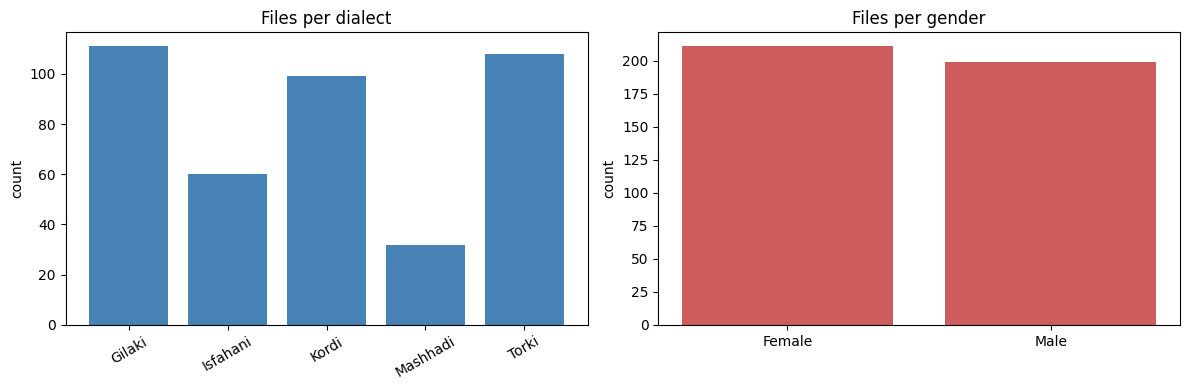

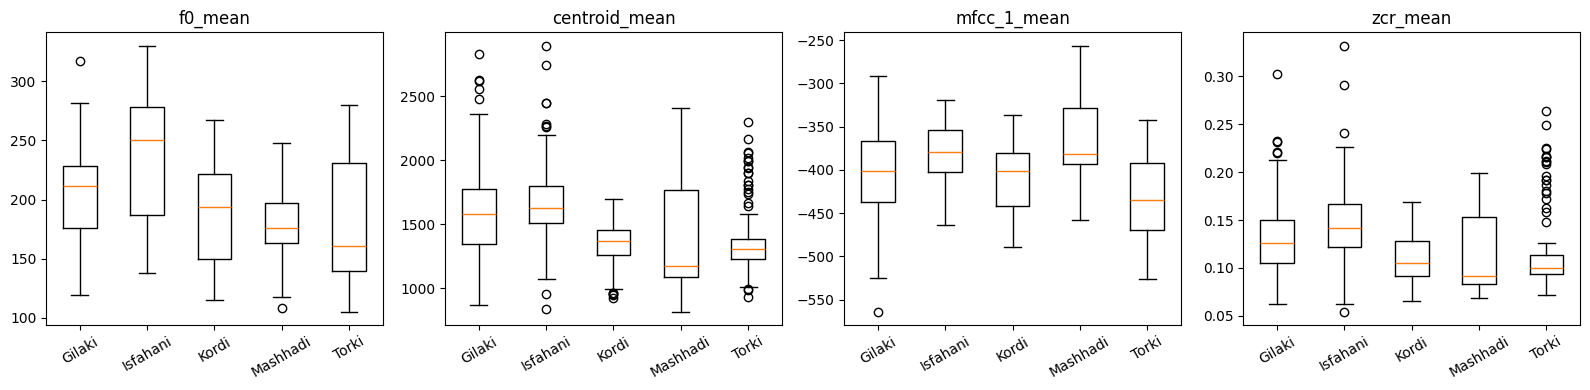

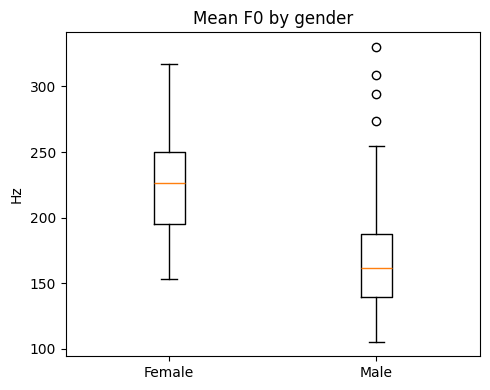


F0 gender test
Female mean: 224.42 Hz | Male mean: 168.60 Hz | t=14.86 | p=4.19e-40

top 12 features by ANOVA F-value
bandwidth_std      42.37
mfcc_4_mean        30.96
contrast_6_mean    29.28
mfcc_2_mean        28.02
contrast_5_mean    24.58
mfcc_8_mean        24.40
rolloff_std        24.28
bandwidth_mean     23.06
f0_mean            22.04
rolloff_mean       21.83
mfcc_1_mean        21.22
f0_std             20.63


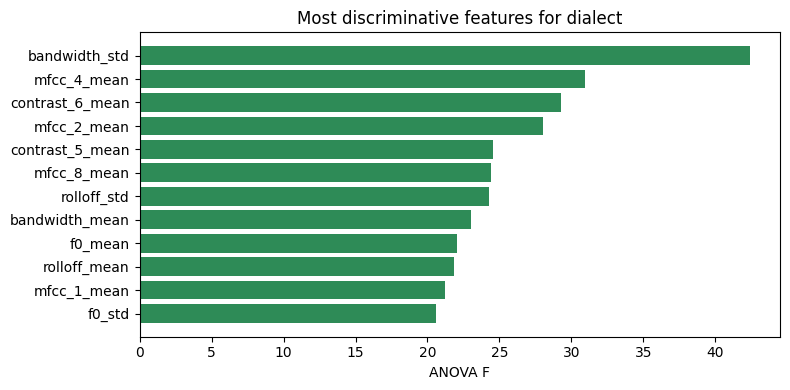


PCA
PC1: 18.70% | PC2: 12.11% | first two: 30.81%


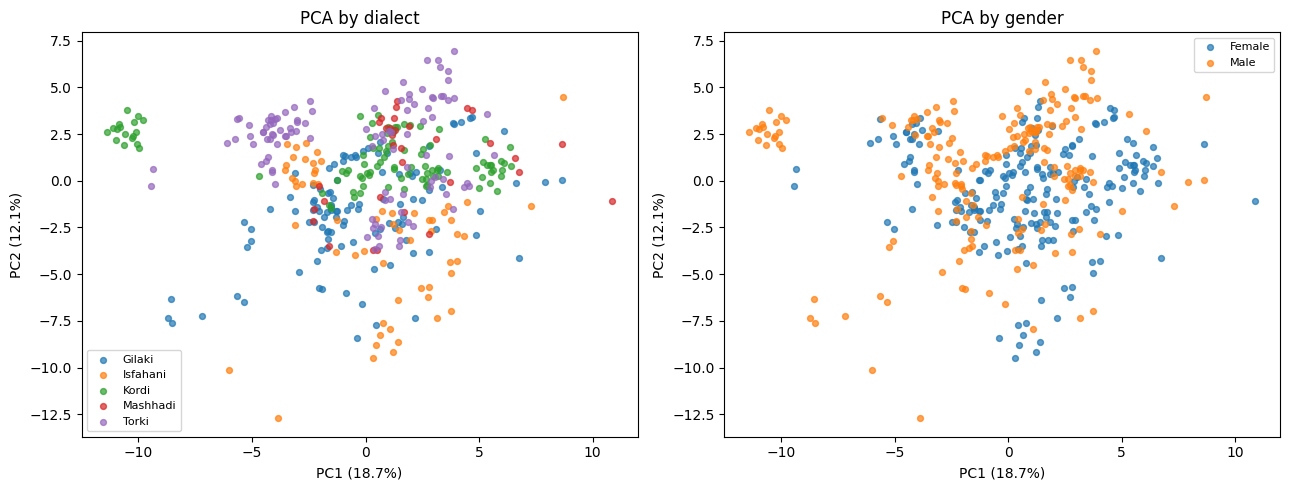


analysis finished
analysis folder: C:\Users\AFSHIN\Desktop\Final-Project-Dataset\Final-Project-Dataset-Preprocessed\analysis_outputs


In [7]:
os.makedirs(analysis_dir, exist_ok=True)

features_df= pd.read_csv(features_csv)

id_cols = [
    "filename",
    "group_id",
    "dialect",
    "gender",
    "speaker_id",
    "voice_id",
    "duration_s"
]

feat_cols= [c for c in features_df.columns if c not in id_cols]

X_all = features_df[feat_cols].to_numpy(dtype=float)
nan_per_col= features_df[feat_cols].isna().sum()
n_inf = int(np.isinf(X_all).sum())

print("========================================")
print("dataset overview")
print("========================================")
print("number of files:", len(features_df))
print("number of features:", len(feat_cols))
print("total columns:", features_df.shape[1])
print("feature columns with NaN:", int((nan_per_col > 0).sum()))
print("total NaN cells:", int(nan_per_col.sum()))
print("total inf cells:", n_inf)

if nan_per_col.sum() > 0:
    print("\ncolumns containing NaN:")
    print(nan_per_col[nan_per_col > 0].to_string())

print("\n========================================")
print("dialect counts")
print("========================================")
print(features_df["dialect"].value_counts().sort_index().to_string())

print("\n========================================")
print("gender counts")
print("========================================")
print(features_df["gender"].value_counts().sort_index().to_string())

print("\n========================================")
print("dialect x gender counts")
print("========================================")
print(features_df.groupby(["dialect", "gender"]).size().to_string())

fig, ax= plt.subplots(1, 2, figsize=(12, 4))

d_counts = features_df["dialect"].value_counts().sort_index()
ax[0].bar(d_counts.index.astype(str), d_counts.values, color="steelblue")
ax[0].set_title("Files per dialect")
ax[0].set_ylabel("count")
ax[0].tick_params(axis="x", rotation=30)

g_counts= features_df["gender"].value_counts().sort_index()
ax[1].bar(g_counts.index.astype(str), g_counts.values, color="indianred")
ax[1].set_title("Files per gender")
ax[1].set_ylabel("count")

plt.tight_layout()
plt.savefig(os.path.join(analysis_dir, "class_balance.png"), dpi=300)
plt.show()

key_feats = ["f0_mean", "centroid_mean", "mfcc_1_mean", "zcr_mean"]
key_feats= [f for f in key_feats if f in feat_cols]
dialects = sorted(features_df["dialect"].dropna().unique())

if len(key_feats) > 0 and len(dialects) > 0:
    fig, axes = plt.subplots(1, len(key_feats), figsize=(4 * len(key_feats), 4))

    if len(key_feats)== 1:
        axes= [axes]

    for ax, feat in zip(axes, key_feats):
        data = [
            features_df.loc[
                features_df["dialect"] == d,
                feat
            ].dropna().values
            for d in dialects
        ]

        ax.boxplot(data)
        ax.set_xticks(range(1, len(dialects) + 1))
        ax.set_xticklabels(dialects, rotation=30)
        ax.set_title(feat)

    plt.tight_layout()
    plt.savefig(os.path.join(analysis_dir, "key_features_by_dialect.png"), dpi=300)
    plt.show()

if "f0_mean" in feat_cols:
    genders= sorted(features_df["gender"].dropna().unique())

    if len(genders)>0:
        data= [
            features_df.loc[
                features_df["gender"] == g,
                "f0_mean"
            ].dropna().values
            for g in genders
        ]

        plt.figure(figsize=(5, 4))
        plt.boxplot(data)
        plt.xticks(range(1, len(genders) + 1), genders)
        plt.title("Mean F0 by gender")
        plt.ylabel("Hz")
        plt.tight_layout()
        plt.savefig(os.path.join(analysis_dir, "f0_by_gender.png"), dpi=300)
        plt.show()

        if len(genders) == 2:
            a, b= data

            if len(a) > 1 and len(b) > 1:
                t, p = stats.ttest_ind(a, b, equal_var=False)

                print("\n========================================")
                print("F0 gender test")
                print("========================================")
                print(
                    f"{genders[0]} mean: {np.mean(a):.2f} Hz | "
                    f"{genders[1]} mean: {np.mean(b):.2f} Hz | "
                    f"t={t:.2f} | p={p:.2e}"
                )

def anova_f(df, feat, group_col):
    groups= [
        df.loc[df[group_col] == g, feat].dropna().values
        for g in df[group_col].dropna().unique()
    ]

    groups = [g for g in groups if len(g) > 1]

    if len(groups) < 2:
        return np.nan

    return stats.f_oneway(*groups).statistic

scores= {
    f: anova_f(features_df, f, "dialect")
    for f in feat_cols
}

ranking = pd.Series(scores).dropna().sort_values(ascending=False)

print("\n========================================")
print("top 12 features by ANOVA F-value")
print("========================================")
print(ranking.head(12).round(2).to_string())

if len(ranking) > 0:
    plt.figure(figsize=(8, 4))
    top= ranking.head(12)[::-1]
    plt.barh(top.index, top.values, color="seagreen")
    plt.xlabel("ANOVA F")
    plt.title("Most discriminative features for dialect")
    plt.tight_layout()
    plt.savefig(os.path.join(analysis_dir, "top_anova_features.png"), dpi=300)
    plt.show()

X= features_df[feat_cols].to_numpy(dtype=float)
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

mu= X.mean(axis=0)
sd = X.std(axis=0)
sd[sd == 0] = 1.0

Xs= (X-mu)/ sd

U, S, Vt = np.linalg.svd(Xs, full_matrices=False)

PC= U[:, :2]*S[:2]
ev = (S**2)/ np.sum(S**2)

print("\n========================================")
print("PCA")
print("========================================")
print(
    f"PC1: {ev[0]*100:.2f}% | "
    f"PC2: {ev[1]*100:.2f}% | "
    f"first two: {ev[:2].sum() * 100:.2f}%"
)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for d in sorted(features_df["dialect"].dropna().unique()):
    m= (features_df["dialect"] == d).values
    ax[0].scatter(PC[m, 0], PC[m, 1], s=18, alpha=0.7, label=d)

ax[0].set_title("PCA by dialect")
ax[0].set_xlabel(f"PC1 ({ev[0]*100:.1f}%)")
ax[0].set_ylabel(f"PC2 ({ev[1]* 100:.1f}%)")
ax[0].legend(fontsize=8)

for g in sorted(features_df["gender"].dropna().unique()):
    m = (features_df["gender"] == g).values
    ax[1].scatter(PC[m, 0], PC[m, 1], s=18, alpha=0.7, label=g)

ax[1].set_title("PCA by gender")
ax[1].set_xlabel(f"PC1 ({ev[0]*100:.1f}%)")
ax[1].set_ylabel(f"PC2 ({ev[1]* 100:.1f}%)")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(analysis_dir, "pca_projection.png"), dpi=300)
plt.show()

ranking.to_csv(
    os.path.join(analysis_dir, "anova_feature_ranking.csv"),
    header=["anova_f"],
    encoding="utf-8-sig"
)

print("\n========================================")
print("analysis finished")
print("analysis folder:", analysis_dir)
print("========================================")
